In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets


In [2]:
class LDA:
    def __init__(self, n_components):
        self.n_components = n_components
        self.linear_discriminants = None # Store the eigenvector computed

    def fit(self, X, y):
        n_features = X.shape[1] # 150, 4 (iris dataset)
        class_labels = np.unique(y)

        # Calculate S_W, S_B
        mean_overall = np.mean(X, axis=0)
        S_W = np.zeros((n_features, n_features)) # 4, 4
        S_B = np.zeros((n_features, n_features)) # 4, 4

        for c in class_labels:
            X_c = X[y == c]
            mean_c = np.mean(X_c, axis=0)

            # (4, n_c) * (n_c, 4) = (4, 4)
            S_W += (X_c - mean_c).T.dot(X_c - mean_c)

            n_c = X_c.shape[0] # number of samples in classe C
            # (4, 1) * (1, 4) = (4, 4)
            mean_diff = (mean_c - mean_overall).reshape(n_features, 1) # (4, 1)

            S_B += n_c * (mean_diff).dot(mean_diff.T)

        A = np.linalg.inv(S_W).dot(S_B)
        eigenvalues, eigenvectors = np.linalg.eig(A)
        eigenvectors = eigenvectors.T
        idxs = np.argsort(abs(eigenvalues))[::-1]
        eigenvalues = eigenvalues[idxs]
        eigenvectors = eigenvectors[idxs]

        self.linear_discriminants = eigenvectors[0:self.n_components]

    def transform(self, X):
        return np.dot(X, self.linear_discriminants.T) # Project the data into the linear discriminant vector (w) calculated


In [3]:
data = datasets.load_wine()
X = data.data
y = data.target
print(X.shape)
print(y.shape)


(178, 13)
(178,)


## Perform PCA


In [4]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)


In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


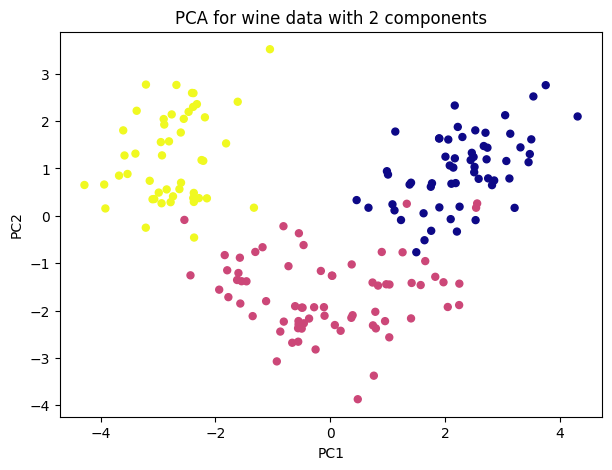

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=[7, 5])

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=25, cmap='plasma')
plt.title('PCA for wine data with 2 components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.savefig("PCA.png")


In [7]:
exp_var = sum(pca.explained_variance_ratio_ * 100)
print('Variance explained:', exp_var)


Variance explained: 55.40633835693528


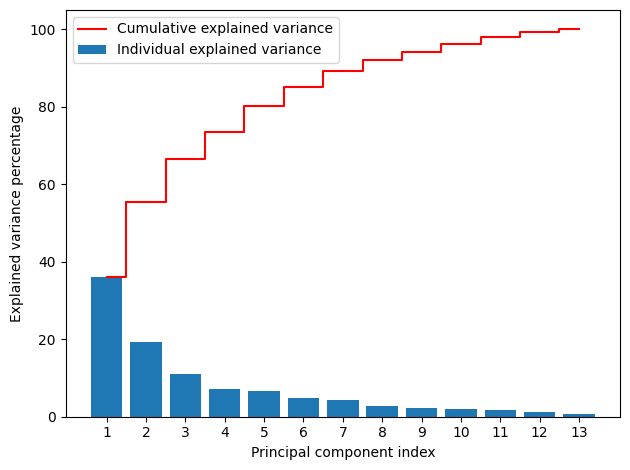

In [8]:
import numpy as np

pca = PCA(n_components=None)
X_pca = pca.fit_transform(X_scaled)

exp_var = pca.explained_variance_ratio_ * 100
cum_exp_var = np.cumsum(exp_var)

plt.bar(range(1, 14), exp_var, align='center',
        label='Individual explained variance')

plt.step(range(1, 14), cum_exp_var, where='mid',
         label='Cumulative explained variance', color='red')

plt.ylabel('Explained variance percentage')
plt.xlabel('Principal component index')
plt.xticks(ticks=list(range(1, 14)))
plt.legend(loc='best')
plt.tight_layout()

plt.savefig("Barplot_PCA.png")


## Perform 
Feature standardization is not needed for LDA as it does not have any effect on the performance of the LDA model.


In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda_sklearn = LinearDiscriminantAnalysis(n_components=2)
X_lda_sklearn = lda_sklearn.fit_transform(X, y)

lda = LDA(n_components=2)
lda.fit(X, y)
X_lda = lda.transform(X)

print("Shape of X:", X.shape)
print("Shape of transformed X:", X_lda.shape)


Shape of X: (178, 13)
Shape of transformed X: (178, 2)


/home/samuel/projects/machine-learning-from-scratch/.venv/lib/python3.10/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/samuel/projects/machine-learning-from-scratch/.venv/lib/python3.10/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


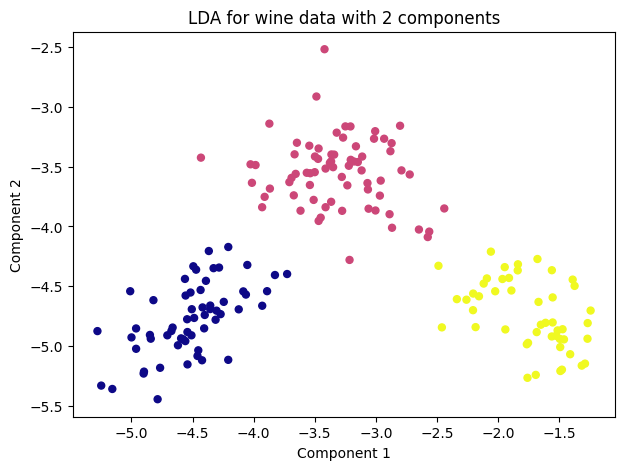

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=[7, 5])

plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y, s=25, cmap='plasma')
plt.title('LDA for wine data with 2 components')
plt.xlabel('Component 1')
plt.ylabel('Component 2')
plt.savefig("LDA.png")


In [11]:
exp_var = sum(lda_sklearn.explained_variance_ratio_ * 100)
print('Variance explained:', exp_var)


Variance explained: 99.99999999999999


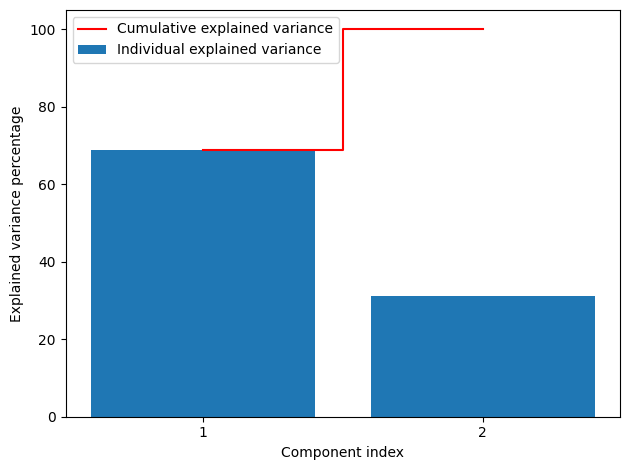

In [12]:
lda = LinearDiscriminantAnalysis(n_components=None)
X_lda = lda.fit(X, y)

exp_var = lda.explained_variance_ratio_ * 100
cum_exp_var = np.cumsum(exp_var)

plt.bar(range(1, 3), exp_var, align='center',
        label='Individual explained variance')

plt.step(range(1, 3), cum_exp_var, where='mid',
         label='Cumulative explained variance', color='red')

plt.ylabel('Explained variance percentage')
plt.xlabel('Component index')
plt.xticks(ticks=[1, 2])
plt.legend(loc='best')
plt.tight_layout()

plt.savefig("Barplot_LDA.png")
